
# Lab 10 — Midsem Questions 2, 4, 5 and BERT Fine-tuning for Language Identification

**Introduction to LLM (AI463) · Lab Assignment 10**

| Part | Task | Where |
|---|---|---|
| **1** | Solve **Question 2** (beam search), **Question 4** (BPE) and **Question 5** (TF-IDF, class representation, Doc2Vec) of the mid-semester paper — written answer **and** code | *Part 1* below (Questions 2, 4, 5) |
| **2** | Fine-tune a **BERT** model on the language-identification dataset built in the earlier lab, and **compare** it with Logistic Regression, MLP, LSTM, GRU and FastText classifiers | *Part 2* below (BERT) |

Part 1 needs only `numpy`, `pandas`, `matplotlib` (`gensim` optional). Part 2 needs `torch` and `transformers` and takes much longer to run – read its first cells for the speed-up options.

---
# PART 1 — Mid-semester questions 2, 4 and 5


## Setup

Everything in the midsem part uses only `numpy`, `pandas` and `matplotlib` (plus optional `torch`, `gensim`, `scikit-learn` for a few demos/cross-checks, each wrapped so the notebook still runs if one is missing).

In [1]:
import math, re, itertools
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

def box(ax, x, y, w, h, text, fc="#dbeafe", ec="#1e3a8a", fs=9):
    """Rounded box with centred text (used for the architecture drawings)."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, x1, y1, x2, y2, text=None, color="#334155"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, lw=1.3, color=color))
    if text:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, text, ha="center", fontsize=8, color=color)

print("Setup done.")

Setup done.


## Question 2 — Beam search decoding with beam width k = 2  `[CO1] [4+1+1=6]`

**Problem.** A neural language model over $V=\{\text{cat, sat, mat, </s>}\}$ gives the conditional probabilities $P(w_t\mid w_1,\dots,w_{t-1})$ listed in the question. Trace beam search with $k=2$ over $t=1,2,3$.

### Idea of beam search

Greedy decoding keeps only the single best word at every step and can miss a better sentence. **Beam search keeps the $k$ best *partial sentences* (hypotheses)** at every step:

1. Start with one hypothesis: the empty prefix after `<s>`, score $1$.
2. **Expand** each kept hypothesis with every possible next word; the new score is the **cumulative probability**
$$P(w_1\dots w_t)=P(w_1\dots w_{t-1})\cdot P(w_t\mid w_1\dots w_{t-1})$$
3. Out of **all** expanded hypotheses (from all beams together) **keep only the top $k$**; discard the rest (**pruning**).
4. Repeat until the last step; the best surviving hypothesis is the output.

(In practice log-probabilities $\sum\log P$ are added instead of multiplying probabilities, to avoid underflow; the ranking is identical.)

### Hand trace

**t = 1** (expand `<s>`): cat = 0.5, sat = 0.3, mat = 0.2 → keep top 2: **cat (0.5)**, **sat (0.3)**; `mat (0.2)` is pruned.

**t = 2:**

| from | expansion | cumulative probability |
|---|---|---|
| cat (0.5) | cat **sat** | 0.5 × 0.6 = **0.30** ✔ |
| cat (0.5) | cat mat | 0.5 × 0.3 = 0.15 |
| cat (0.5) | cat </s> | 0.5 × 0.1 = 0.05 |
| sat (0.3) | sat cat | 0.3 × 0.2 = 0.06 |
| sat (0.3) | sat **mat** | 0.3 × 0.7 = **0.21** ✔ |
| sat (0.3) | sat </s> | 0.3 × 0.1 = 0.03 |

Top 2 kept: **cat sat (0.30)**, **sat mat (0.21)**.

**t = 3:**

| from | expansion | cumulative probability |
|---|---|---|
| cat sat (0.30) | cat sat **mat** | 0.30 × 0.8 = **0.24** ✔ |
| cat sat (0.30) | cat sat </s> | 0.30 × 0.2 = 0.06 |
| sat mat (0.21) | sat mat cat | 0.21 × 0.1 = 0.021 |
| sat mat (0.21) | sat mat **</s>** | 0.21 × 0.9 = **0.189** ✔ |

Top 2 kept: **cat sat mat (0.24)**, **sat mat </s> (0.189)**.

**Final output: `cat sat mat` with probability 0.24.** (Length-normalised scores $P^{1/3}$ give 0.621 vs 0.574, so the same hypothesis wins. If one insists on a sentence that already *ended* with `</s>`, the best finished one is `sat mat </s>` = 0.189.)

### Why do we ignore $P(\text{cat}\mid\text{mat})$ and $P(\text{sat}\mid\text{mat})$?

Because the hypothesis ending in `mat` was **pruned**. At $t=1$ `mat` (0.2) is not among the top $k=2$, so it is never expanded; those probabilities would only be needed to extend the prefix `mat`. (Likewise `cat mat` (0.15) was pruned at $t=2$.) Beam search only computes next-word distributions for the **surviving** hypotheses – that is exactly what makes it cheaper than exhaustive search.

### Code

In [2]:
EOS = "</s>"

# Conditional probabilities exactly as given in the question, keyed by the prefix (history of words so far)
COND = {
    ():              {"cat": 0.5, "sat": 0.3, "mat": 0.2},                 # t=1, given <s>
    ("cat",):        {"sat": 0.6, "mat": 0.3, EOS: 0.1},                   # t=2
    ("sat",):        {"cat": 0.2, "mat": 0.7, EOS: 0.1},
    ("cat", "sat"):  {"mat": 0.8, EOS: 0.2},                               # t=3
    ("sat", "mat"):  {"cat": 0.1, EOS: 0.9},
}

def next_dist(prefix):
    if prefix not in COND:
        raise KeyError(f"P(. | {' '.join(prefix)}) is not available - this hypothesis should have been pruned")
    return COND[prefix]

def beam_search(k, steps=3):
    """Returns (final beam, list of per-step tables). Each hypothesis = (tuple_of_words, cumulative_probability)."""
    beam = [((), 1.0)]
    tables = []
    for t in range(1, steps + 1):
        candidates = []
        for prefix, p in beam:
            if prefix and prefix[-1] == EOS:                  # finished hypothesis: carry over unchanged
                candidates.append((prefix, p, f"{p:.4g} (finished)"))
                continue
            for w, pw in next_dist(prefix).items():
                candidates.append((prefix + (w,), p * pw, f"{p:.4g} x {pw}"))
        candidates.sort(key=lambda x: -x[1])
        kept = candidates[:k]
        tables.append(pd.DataFrame({
            "hypothesis": [" ".join(c[0]) for c in candidates],
            "computation": [c[2] for c in candidates],
            "cumulative P": [c[1] for c in candidates],
            "kept (top-%d)" % k: ["YES" if i < k else "pruned" for i in range(len(candidates))],
        }))
        beam = [(c[0], c[1]) for c in kept]
    return beam, tables

beam, tables = beam_search(k=2, steps=3)
for t, tab in enumerate(tables, start=1):
    print(f"\n=== t = {t} ===")
    display(tab.round(4))

best_seq, best_p = beam[0]
print("\nFinal beam:", [(" ".join(s), round(p, 4)) for s, p in beam])
print("FINAL OUTPUT:", " ".join(best_seq), f"  (P = {best_p:.4f})")


=== t = 1 ===


,hypothesis,computation,cumulative P,kept (top-2)
0,cat,1 x 0.5,0.5,YES
1,sat,1 x 0.3,0.3,YES
2,mat,1 x 0.2,0.2,pruned



=== t = 2 ===


,hypothesis,computation,cumulative P,kept (top-2)
0,cat sat,0.5 x 0.6,0.30,YES
1,sat mat,0.3 x 0.7,0.21,YES
2,cat mat,0.5 x 0.3,0.15,pruned
3,sat cat,0.3 x 0.2,0.06,pruned
4,cat </s>,0.5 x 0.1,0.05,pruned
5,sat </s>,0.3 x 0.1,0.03,pruned



=== t = 3 ===


,hypothesis,computation,cumulative P,kept (top-2)
0,cat sat mat,0.3 x 0.8,0.240,YES
1,sat mat </s>,0.21 x 0.9,0.189,YES
2,cat sat </s>,0.3 x 0.2,0.060,pruned
3,sat mat cat,0.21 x 0.1,0.021,pruned



Final beam: [('cat sat mat', 0.24), ('sat mat </s>', 0.189)]
FINAL OUTPUT: cat sat mat   (P = 0.2400)


### Check 1 — compare with greedy decoding and exhaustive search

Greedy keeps only one hypothesis ($k=1$); exhaustive search scores **every** sequence the table allows. Beam search with $k=2$ should find the best 3-word sequence here.

In [3]:
greedy, _ = beam_search(k=1, steps=3)
print("Greedy (k=1)      :", " ".join(greedy[0][0]), round(greedy[0][1], 4))

# exhaustive search over every path the probability table defines
def all_paths(prefix=(), p=1.0, depth=3):
    if depth == 0 or (prefix and prefix[-1] == EOS):
        yield prefix, p
        return
    if prefix not in COND:                     # table gives no continuation (e.g. 'mat', 'cat mat') -> stop
        return
    for w, pw in COND[prefix].items():
        yield from all_paths(prefix + (w,), p * pw, depth - 1)

paths = sorted(all_paths(), key=lambda x: -x[1])
print("Exhaustive search, best 3 paths:")
for s, p in paths[:3]:
    print("   ", " ".join(s), round(p, 4))
print("Beam (k=2) found the best path:", " ".join(beam[0][0]) == " ".join(paths[0][0]))

Greedy (k=1)      : cat sat mat 0.24
Exhaustive search, best 3 paths:
    cat sat mat 0.24
    sat mat </s> 0.189
    cat sat </s> 0.06
Beam (k=2) found the best path: True


### Check 2 — "why ignore P(cat|mat), P(sat|mat)?" demonstrated

With a **wider beam ($k=3$)** the hypothesis `mat` *would* survive step 1 and its next-word distribution would be needed – but the question does not provide it, and the code raises exactly that error. With $k=2$ it is never requested.

In [4]:
try:
    beam_search(k=3, steps=3)
except KeyError as e:
    print("k = 3 needs a distribution the question does not give ->", e)
print("k = 2 never asks for P(. | mat): OK (see the t=1 table above, 'mat' is pruned)")

k = 3 needs a distribution the question does not give -> 'P(. | mat) is not available - this hypothesis should have been pruned'
k = 2 never asks for P(. | mat): OK (see the t=1 table above, 'mat' is pruned)


## Question 4 — Byte-Pair Encoding (2 merges)  `[CO2] [2+2+2=6]`

**Corpus**

```
low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest
```

### How BPE works

1. Split every word into **characters** and append an **end-of-word marker `</w>`** (so that the model knows where a word ends, e.g. `est</w>` at a word end is different from `est` inside a word).
2. **Count every pair of adjacent symbols**, weighted by the word frequency.
3. **Merge the most frequent pair** into one new symbol and record it as a **merge rule**.
4. Repeat for the wanted number of merges (here 2). The **vocabulary** = all single characters (incl. `</w>`) + the merged symbols.

### Step 0 — word frequencies

| word | low | lower | lowest | new | newest | widest |
|---|---|---|---|---|---|---|
| count | 5 | 2 | 3 | 2 | 1 | 3 |

(low: 2+2+1 = 5, lower: 2, lowest: 1+2 = 3, new: 1+1 = 2, newest: 1, widest: 2+1 = 3)

### Steps 1 and 2

The most frequent pairs are computed in the code below. In short: `(l,o)` and `(o,w)` both occur **10** times (low 5 + lower 2 + lowest 3). Ties are broken by the **first pair encountered** → merge 1 = **`l o → lo`**; then `(lo,w)` has 10 → merge 2 = **`lo w → low`**. (Breaking the first tie the other way, `o w → ow` then `l ow → low`, gives the **same** vocabulary except for the name of the intermediate symbol, and identical segmentations after 2 merges.)

### Code — BPE learning with a full trace

In [5]:
from collections import Counter

corpus_text = """low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest"""

word_freq = Counter(corpus_text.split())
print("Word frequencies:", dict(word_freq))

# word (as a tuple of symbols, with </w>) -> frequency
def init_vocab(word_freq):
    return {tuple(w) + ("</w>",): f for w, f in word_freq.items()}

def pair_counts(vocab):
    counts = {}                                 # insertion order = order of first occurrence (used for tie-breaking)
    for symbols, f in vocab.items():
        for a, b in zip(symbols, symbols[1:]):
            counts[(a, b)] = counts.get((a, b), 0) + f
    return counts

def merge_pair(vocab, pair):
    new_vocab = {}
    for symbols, f in vocab.items():
        out, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
                out.append(symbols[i] + symbols[i + 1]); i += 2
            else:
                out.append(symbols[i]); i += 1
        new_vocab[tuple(out)] = new_vocab.get(tuple(out), 0) + f
    return new_vocab

def learn_bpe(word_freq, num_merges, verbose=True):
    vocab = init_vocab(word_freq)
    merges = []
    if verbose:
        print("Initial segmentation:")
        for s, f in vocab.items():
            print(f"   {' '.join(s):<28} x{f}")
    for step in range(1, num_merges + 1):
        counts = pair_counts(vocab)
        best = max(counts, key=counts.get)      # first maximum wins ties
        if verbose:
            top = sorted(counts.items(), key=lambda kv: -kv[1])[:6]
            print(f"\n--- merge {step}: top pair counts ---")
            print("   " + ", ".join(f"{a}+{b}:{c}" for (a, b), c in top))
            ties = [p for p, c in counts.items() if c == counts[best]]
            print(f"   chosen: {best}  (count {counts[best]}; tied pairs: {ties})")
        vocab = merge_pair(vocab, best)
        merges.append(best)
        if verbose:
            for s, f in vocab.items():
                print(f"   {' '.join(s):<28} x{f}")
    return vocab, merges

final_vocab, merges = learn_bpe(word_freq, num_merges=2)
print("\nMERGE RULES (in order):")
for i, m in enumerate(merges, 1):
    print(f"   {i}. {m[0]} + {m[1]}  ->  {m[0] + m[1]}")

Word frequencies: {'low': 5, 'lower': 2, 'lowest': 3, 'new': 2, 'newest': 1, 'widest': 3}
Initial segmentation:
   l o w </w>                   x5
   l o w e r </w>               x2
   l o w e s t </w>             x3
   n e w </w>                   x2
   n e w e s t </w>             x1
   w i d e s t </w>             x3

--- merge 1: top pair counts ---
   l+o:10, o+w:10, w+</w>:7, e+s:7, s+t:7, t+</w>:7
   chosen: ('l', 'o')  (count 10; tied pairs: [('l', 'o'), ('o', 'w')])
   lo w </w>                    x5
   lo w e r </w>                x2
   lo w e s t </w>              x3
   n e w </w>                   x2
   n e w e s t </w>             x1
   w i d e s t </w>             x3

--- merge 2: top pair counts ---
   lo+w:10, w+</w>:7, e+s:7, s+t:7, t+</w>:7, w+e:6
   chosen: ('lo', 'w')  (count 10; tied pairs: [('lo', 'w')])
   low </w>                     x5
   low e r </w>                 x2
   low e s t </w>               x3
   n e w </w>                   x2
   n e w e s t </w>   

In [6]:
base_symbols = sorted({s for symbols in init_vocab(word_freq) for s in symbols})
merged_symbols = [a + b for a, b in merges]
final_symbols = base_symbols + merged_symbols
print("FINAL VOCABULARY after 2 merges  (size = %d):" % len(final_symbols))
print("   characters :", base_symbols)
print("   merged     :", merged_symbols)

print("\nSegmentation of the training words:")
seg = pd.DataFrame([{"word": "".join(s).replace("</w>", ""), "count": f, "BPE tokens": " ".join(s)}
                    for s, f in final_vocab.items()])
display(seg)

FINAL VOCABULARY after 2 merges  (size = 13):
   characters : ['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']
   merged     : ['lo', 'low']

Segmentation of the training words:


,word,count,BPE tokens
0,low,5,low </w>
1,lower,2,low e r </w>
2,lowest,3,low e s t </w>
3,new,2,n e w </w>
4,newest,1,n e w e s t </w>
5,widest,3,w i d e s t </w>


**Result.** Merge rules: **(1) `l o → lo`**, **(2) `lo w → low`**. Vocabulary = the 11 base symbols `d e i l n o r s t w </w>` + `lo`, `low` = **13 symbols**. (`l` and `o` no longer appear on their own in the segmented corpus, but they stay in the vocabulary because they are needed to spell unseen words.)

### How does BPE handle out-of-vocabulary words?

BPE never needs an "unknown word": at test time a new word is split into characters + `</w>` and the **learned merge rules are applied in the same order as in training**. A word that was never seen is therefore broken into the **longest known sub-word pieces**, and in the worst case into single characters. Only a **character that is not in the base vocabulary at all** (e.g. a new script) has to be mapped to `<unk>`.

In [7]:
def bpe_encode(word, merges, base_symbols):
    symbols = [c if c in base_symbols else "<unk>" for c in word] + ["</w>"]
    for a, b in merges:                          # apply the rules in the learned order
        i, out = 0, []
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == a and symbols[i + 1] == b:
                out.append(a + b); i += 2
            else:
                out.append(symbols[i]); i += 1
        symbols = out
    return symbols

for w in ["low", "lowest", "slow", "lowly", "newer", "widen", "wild", "xyz"]:
    kind = "seen " if w in word_freq else "OOV  "
    print(f"{kind} {w:<8} ->", bpe_encode(w, merges, set(base_symbols)))
print("\nObservations: 'slow' = s + low + </w> (the known piece 'low' is reused); 'newer', 'widen' fall back to characters;")
print("'xyz' contains characters never seen in training, so they become <unk> (the only real failure case).")

seen  low      -> ['low', '</w>']
seen  lowest   -> ['low', 'e', 's', 't', '</w>']
OOV   slow     -> ['s', 'low', '</w>']
OOV   lowly    -> ['low', 'l', '<unk>', '</w>']
OOV   newer    -> ['n', 'e', 'w', 'e', 'r', '</w>']
OOV   widen    -> ['w', 'i', 'd', 'e', 'n', '</w>']
OOV   wild     -> ['w', 'i', 'l', 'd', '</w>']
OOV   xyz      -> ['<unk>', '<unk>', '<unk>', '</w>']

Observations: 'slow' = s + low + </w> (the known piece 'low' is reused); 'newer', 'widen' fall back to characters;
'xyz' contains characters never seen in training, so they become <unk> (the only real failure case).


## Question 5 — TF-IDF of 4 documents, class representation, Doc2Vec  `[CO1+CO3] [2+2+2=6]`

| Document | Text | Class |
|---|---|---|
| D1 | machine learning is useful | Technology |
| D2 | machine learning is powerful | Technology |
| D3 | learning language is useful | Language |
| D4 | language processing is useful | Language |

### Definitions used (no start/end markers, as required)

$$\text{tf}(t,d)=\frac{\text{count of }t\text{ in }d}{\text{number of words in }d},\qquad \text{idf}(t)=\ln\frac{N}{df(t)},\qquad \text{tf-idf}(t,d)=\text{tf}(t,d)\cdot\text{idf}(t)$$

$N=4$ documents, $df(t)$ = number of documents containing $t$. A word that occurs in **every** document ($df=N$) gets idf $=\ln 1=0$ – it carries no information for telling documents apart. (Other textbooks use $\log_{10}$, raw counts as tf, or the smoothed scikit-learn idf $\ln\frac{1+N}{1+df}+1$; only the scale changes – the code shows these variants too.)

### 5(a) Vocabulary and TF-IDF

**Vocabulary (7 words):** `machine, learning, is, useful, powerful, language, processing`.

| word | df | idf = ln(4/df) |
|---|---|---|
| machine | 2 | ln 2 = 0.6931 |
| learning | 3 | ln(4/3) = 0.2877 |
| is | 4 | ln 1 = 0 |
| useful | 3 | ln(4/3) = 0.2877 |
| powerful | 1 | ln 4 = 1.3863 |
| language | 2 | ln 2 = 0.6931 |
| processing | 1 | ln 4 = 1.3863 |

Every document has 4 words, each word appears once → tf = 1/4 = 0.25, so tf-idf = 0.25 × idf (e.g. D1: machine = 0.1733, learning = 0.0719, is = 0, useful = 0.0719).

### Code

In [8]:
docs = {
    "D1": "machine learning is useful",
    "D2": "machine learning is powerful",
    "D3": "learning language is useful",
    "D4": "language processing is useful",
}
labels = {"D1": "Technology", "D2": "Technology", "D3": "Language", "D4": "Language"}

# vocabulary in order of first appearance
vocab = []
for d in docs.values():
    for w in d.split():
        if w not in vocab:
            vocab.append(w)
N = len(docs)
print("Vocabulary (%d words):" % len(vocab), vocab)

df_counts = {w: sum(w in d.split() for d in docs.values()) for w in vocab}

def compute_tfidf(docs, vocab, log=math.log, tf_mode="relative"):
    idf = {w: log(N / df_counts[w]) for w in vocab}
    rows = {}
    for name, text in docs.items():
        toks = text.split()
        row = []
        for w in vocab:
            c = toks.count(w)
            tf = c / len(toks) if tf_mode == "relative" else c
            row.append(tf * idf[w])
        rows[name] = row
    return pd.DataFrame(rows, index=vocab).T, idf

tfidf_df, idf = compute_tfidf(docs, vocab)
display(pd.DataFrame({"df": df_counts, "idf = ln(N/df)": idf}).T.round(4))
print("TF-IDF matrix (rows = documents, tf = count / doc length, idf = ln(N/df)):")
display(tfidf_df.round(4))

# hand-checks against the table in the markdown above
assert abs(tfidf_df.loc["D1", "machine"] - 0.25 * math.log(2)) < 1e-12
assert abs(tfidf_df.loc["D2", "powerful"] - 0.25 * math.log(4)) < 1e-12
assert (tfidf_df["is"] == 0).all()
print("hand-computed values match.")

Vocabulary (7 words): ['machine', 'learning', 'is', 'useful', 'powerful', 'language', 'processing']


,machine,learning,is,useful,powerful,language,processing
df,2.0000,3.0000,4.0,3.0000,1.0000,2.0000,1.0000
idf = ln(N/df),0.6931,0.2877,0.0,0.2877,1.3863,0.6931,1.3863


TF-IDF matrix (rows = documents, tf = count / doc length, idf = ln(N/df)):


,machine,learning,is,useful,powerful,language,processing
D1,0.1733,0.0719,0.0,0.0719,0.0000,0.0000,0.0000
D2,0.1733,0.0719,0.0,0.0000,0.3466,0.0000,0.0000
D3,0.0000,0.0719,0.0,0.0719,0.0000,0.1733,0.0000
D4,0.0000,0.0000,0.0,0.0719,0.0000,0.1733,0.3466


hand-computed values match.


In [9]:
# variants of the formula (only the scale changes)
tfidf_log10, _ = compute_tfidf(docs, vocab, log=math.log10)
tfidf_rawtf, _ = compute_tfidf(docs, vocab, tf_mode="raw")
print("log10 idf, relative tf:"); display(tfidf_log10.round(4))
print("ln idf, RAW count tf (tf = 1):"); display(tfidf_rawtf.round(4))

try:
    from sklearn.feature_extraction.text import TfidfVectorizer
    tv = TfidfVectorizer(smooth_idf=True, norm=None, vocabulary=vocab)
    sk = pd.DataFrame(tv.fit_transform(list(docs.values())).toarray(), index=list(docs), columns=vocab)
    print("scikit-learn convention (idf = ln((1+N)/(1+df)) + 1, raw tf, no normalisation):")
    display(sk.round(4))
except ImportError:
    print("scikit-learn not installed - skipping the cross-check.")

log10 idf, relative tf:


,machine,learning,is,useful,powerful,language,processing
D1,0.0753,0.0312,0.0,0.0312,0.0000,0.0000,0.0000
D2,0.0753,0.0312,0.0,0.0000,0.1505,0.0000,0.0000
D3,0.0000,0.0312,0.0,0.0312,0.0000,0.0753,0.0000
D4,0.0000,0.0000,0.0,0.0312,0.0000,0.0753,0.1505


ln idf, RAW count tf (tf = 1):


,machine,learning,is,useful,powerful,language,processing
D1,0.6931,0.2877,0.0,0.2877,0.0000,0.0000,0.0000
D2,0.6931,0.2877,0.0,0.0000,1.3863,0.0000,0.0000
D3,0.0000,0.2877,0.0,0.2877,0.0000,0.6931,0.0000
D4,0.0000,0.0000,0.0,0.2877,0.0000,0.6931,1.3863


scikit-learn convention (idf = ln((1+N)/(1+df)) + 1, raw tf, no normalisation):


,machine,learning,is,useful,powerful,language,processing
D1,1.5108,1.2231,1.0,1.2231,0.0000,0.0000,0.0000
D2,1.5108,1.2231,1.0,0.0000,1.9163,0.0000,0.0000
D3,0.0000,1.2231,1.0,1.2231,0.0000,1.5108,0.0000
D4,0.0000,0.0000,1.0,1.2231,0.0000,1.5108,1.9163


### 5(b) How do we represent the **classes** through the TF-IDF of the documents?

Each document is a **7-dimensional TF-IDF vector**. A class is then represented by combining the vectors of its documents. Two standard ways:

1. **Class centroid (Rocchio):** $\;\vec c_k=\dfrac{1}{|D_k|}\sum_{d\in D_k}\vec d_{\text{tf-idf}}$ – the *average* TF-IDF vector of all documents of the class. A new document is assigned to the class whose centroid has the **highest cosine similarity** with it.
2. **Class as one big document:** concatenate all documents of a class into a single pseudo-document and compute TF-IDF over the $K$ class-documents (here $N=2$). The weights then say which words are *characteristic of the class*.

Both give each class a vector over the same vocabulary; the largest components are the words that *characterise* the class.

In [10]:
classes = sorted(set(labels.values()))

# --- way 1: centroids of document TF-IDF vectors ---
centroids = pd.DataFrame({c: tfidf_df.loc[[d for d in docs if labels[d] == c]].mean() for c in classes}).T
print("Class centroids (mean TF-IDF of the class's documents):")
display(centroids.round(4))

for c in classes:
    top = centroids.loc[c].sort_values(ascending=False)
    print(f"  most characteristic words of {c:<10}:", [(w, round(v, 3)) for w, v in top.items() if v > 0][:4])

def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(a @ b / (na * nb)) if na > 0 and nb > 0 else 0.0

def tfidf_vector(text):
    toks = text.split()
    return np.array([(toks.count(w) / len(toks)) * idf[w] if len(toks) else 0 for w in vocab])

print("\nClassifying new sentences by cosine similarity to the class centroids:")
for q in ["machine learning is powerful", "language processing is useful", "learning is useful", "powerful machine"]:
    sims = {c: cosine(tfidf_vector(q), centroids.loc[c].values) for c in classes}
    vals = sorted(sims.values())
    verdict = "tie (no class-specific words)" if abs(vals[-1] - vals[-2]) < 1e-9 else max(sims, key=sims.get)
    print(f"  {q!r:<36}", {c: round(s, 3) for c, s in sims.items()}, "->", verdict)

# --- way 2: one pseudo-document per class ---
class_docs = {c: " ".join(docs[d] for d in docs if labels[d] == c) for c in classes}
Nc = len(class_docs)
df_cls = {w: sum(w in t.split() for t in class_docs.values()) for w in vocab}
rows = {}
for c, text in class_docs.items():
    toks = text.split()
    rows[c] = [(toks.count(w) / len(toks)) * math.log(Nc / df_cls[w]) for w in vocab]
print("\nClass-as-document TF-IDF (N = 2 class documents; words in both classes get weight 0):")
display(pd.DataFrame(rows, index=vocab).T.round(4))

Class centroids (mean TF-IDF of the class's documents):


,machine,learning,is,useful,powerful,language,processing
Language,0.0000,0.0360,0.0,0.0719,0.0000,0.1733,0.1733
Technology,0.1733,0.0719,0.0,0.0360,0.1733,0.0000,0.0000


  most characteristic words of Language  : [('language', 0.173), ('processing', 0.173), ('useful', 0.072), ('learning', 0.036)]
  most characteristic words of Technology: [('machine', 0.173), ('powerful', 0.173), ('learning', 0.072), ('useful', 0.036)]

Classifying new sentences by cosine similarity to the class centroids:
  'machine learning is powerful'       {'Language': 0.025, 'Technology': 0.937} -> Technology
  'language processing is useful'      {'Language': 0.937, 'Technology': 0.025} -> Language
  'learning is useful'                 {'Language': 0.296, 'Technology': 0.296} -> tie (no class-specific words)
  'powerful machine'                   {'Language': 0.0, 'Technology': 0.901} -> Technology

Class-as-document TF-IDF (N = 2 class documents; words in both classes get weight 0):


,machine,learning,is,useful,powerful,language,processing
Language,0.0000,0.0,0.0,0.0,0.0000,0.1733,0.0866
Technology,0.1733,0.0,0.0,0.0,0.0866,0.0000,0.0000


### 5(c) How do we learn document representations with **Doc2Vec**?

TF-IDF vectors are sparse, as long as the vocabulary, and ignore word order. **Doc2Vec (Paragraph Vector, Le & Mikolov 2014)** extends Word2Vec so that every document gets its own **dense vector learned by prediction**. A unique **paragraph (document) ID** is added as an extra "word" whose vector $\vec p_d$ is trained together with the word vectors:

* **PV-DM (Distributed Memory)** – extension of **CBOW**: the document vector **and** the context words are combined (average or concatenation) to **predict the next/middle word**. The document vector acts as a memory of what the context alone cannot say.
* **PV-DBOW (Distributed Bag of Words)** – extension of **Skip-gram**: the document vector alone predicts words sampled from the document.

At inference time for a **new** document, the network weights are frozen and only a fresh paragraph vector is trained for a few steps. (Technique name to write in the exam: **Doc2Vec — PV-DM / PV-DBOW**.)

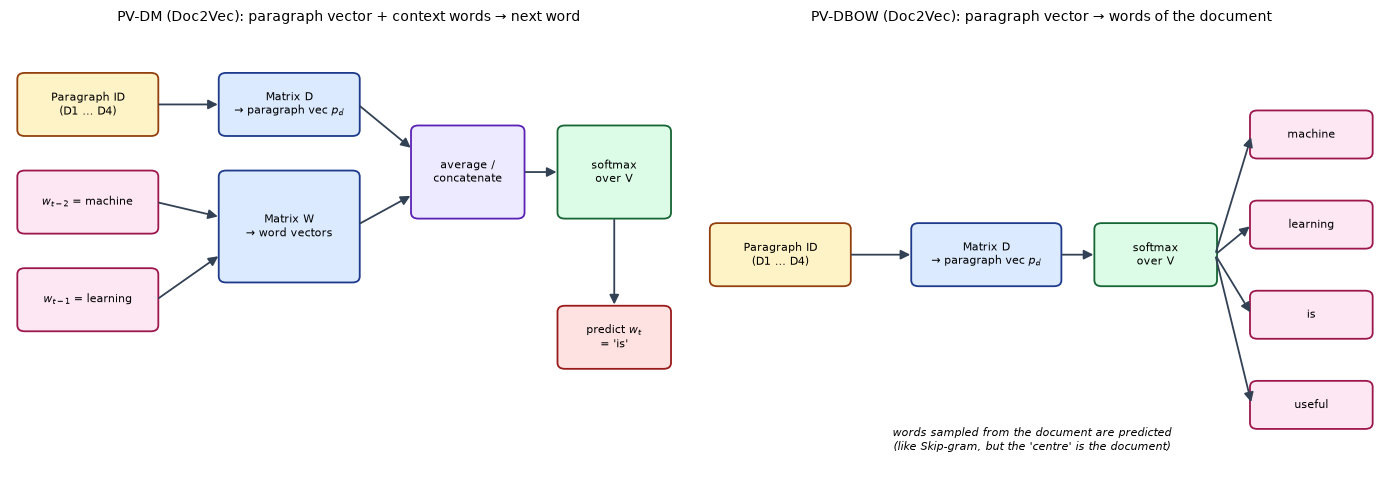

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---------- PV-DM ----------
ax = axes[0]; ax.set_xlim(0, 7.4); ax.set_ylim(0, 6); ax.axis("off")
box(ax, 0.1, 4.6, 1.5, 0.8, "Paragraph ID\n(D1 … D4)", fc="#fef3c7", ec="#92400e", fs=8)
box(ax, 0.1, 3.3, 1.5, 0.8, "$w_{t-2}$ = machine", fc="#fce7f3", ec="#9d174d", fs=8)
box(ax, 0.1, 2.0, 1.5, 0.8, "$w_{t-1}$ = learning", fc="#fce7f3", ec="#9d174d", fs=8)
box(ax, 2.3, 4.6, 1.5, 0.8, "Matrix D\n→ paragraph vec $p_d$", fc="#dbeafe", fs=8)
box(ax, 2.3, 2.65, 1.5, 1.45, "Matrix W\n→ word vectors", fc="#dbeafe", fs=8)
box(ax, 4.4, 3.5, 1.2, 1.2, "average /\nconcatenate", fc="#ede9fe", ec="#5b21b6", fs=8)
box(ax, 6.0, 3.5, 1.2, 1.2, "softmax\nover V", fc="#dcfce7", ec="#166534", fs=8)
box(ax, 6.0, 1.5, 1.2, 0.8, "predict $w_t$\n= 'is'", fc="#fee2e2", ec="#991b1b", fs=8)
arrow(ax, 1.6, 5.0, 2.3, 5.0); arrow(ax, 1.6, 3.7, 2.3, 3.5); arrow(ax, 1.6, 2.4, 2.3, 3.0)
arrow(ax, 3.8, 5.0, 4.4, 4.4); arrow(ax, 3.8, 3.4, 4.4, 3.8); arrow(ax, 5.6, 4.1, 6.0, 4.1); arrow(ax, 6.6, 3.5, 6.6, 2.3)
ax.set_title("PV-DM (Doc2Vec): paragraph vector + context words → next word", fontsize=10)

# ---------- PV-DBOW ----------
ax = axes[1]; ax.set_xlim(0, 7.4); ax.set_ylim(0, 6); ax.axis("off")
box(ax, 0.1, 2.6, 1.5, 0.8, "Paragraph ID\n(D1 … D4)", fc="#fef3c7", ec="#92400e", fs=8)
box(ax, 2.3, 2.6, 1.6, 0.8, "Matrix D\n→ paragraph vec $p_d$", fc="#dbeafe", fs=8)
box(ax, 4.3, 2.6, 1.3, 0.8, "softmax\nover V", fc="#dcfce7", ec="#166534", fs=8)
for yy, wd in zip((4.6, 3.4, 2.2, 1.0), ("machine", "learning", "is", "useful")):
    box(ax, 6.0, yy - 0.3, 1.3, 0.6, wd, fc="#fce7f3", ec="#9d174d", fs=8)
    arrow(ax, 5.6, 3.0, 6.0, yy)
arrow(ax, 1.6, 3.0, 2.3, 3.0); arrow(ax, 3.9, 3.0, 4.3, 3.0)
ax.text(3.6, 0.4, "words sampled from the document are predicted\n(like Skip-gram, but the 'centre' is the document)", ha="center", fontsize=8, style="italic")
ax.set_title("PV-DBOW (Doc2Vec): paragraph vector → words of the document", fontsize=10)
plt.tight_layout(); plt.show()

Optional demo – train a real Doc2Vec model (gensim) on the 4 documents. With only 4 very short documents the vectors are not meaningful; the point is to see the API and the shape of the result.

In [12]:
try:
    from gensim.models.doc2vec import Doc2Vec, TaggedDocument
    tagged = [TaggedDocument(words=t.split(), tags=[d]) for d, t in docs.items()]
    for name, dm in [("PV-DM", 1), ("PV-DBOW", 0)]:
        model = Doc2Vec(tagged, vector_size=8, window=2, min_count=1, dm=dm, epochs=200, seed=1, workers=1)
        vecs = np.array([model.dv[d] for d in docs])
        print(f"{name}: document-vector matrix shape = {vecs.shape}")
        print("   cos(D1,D2) =", round(cosine(vecs[0], vecs[1]), 3), "  cos(D3,D4) =", round(cosine(vecs[2], vecs[3]), 3),
              "  cos(D1,D4) =", round(cosine(vecs[0], vecs[3]), 3))
    new_vec = model.infer_vector("machine learning is useful".split())
    print("inferred vector for a new text:", np.round(new_vec[:4], 3), "...")
except ImportError:
    print("gensim not installed - run `%pip install gensim` to try the demo.")

PV-DM: document-vector matrix shape = (4, 8)
   cos(D1,D2) = 0.478   cos(D3,D4) = 0.199   cos(D1,D4) = 0.034
PV-DBOW: document-vector matrix shape = (4, 8)
   cos(D1,D2) = 0.565   cos(D3,D4) = 0.146   cos(D1,D4) = 0.071
inferred vector for a new text: [-0.06   0.033 -0.092  0.043] ...


---
# PART 2 — BERT fine-tuning for language identification
(the numbering below restarts; Section 1 here means the BERT set-up.)

# Part 2 — Fine-tune BERT for Language Identification and compare with the earlier models

**Task (from the assignment).** Take the **language-identification dataset built in the earlier lab** (5 Indian languages, `langid_train/val/test.csv`), **fine-tune a multilingual BERT model** on it, and **compare its performance** with the classifiers built earlier: Logistic Regression, MLP ($n=0,1,2$), LSTM, GRU and FastText supervised classification.

### Plan

| Step | What happens |
|---|---|
| 1 | Install / configure, choose the BERT model and device (CUDA → Apple-silicon MPS → CPU) |
| 2 | Load the **same** train / val / test CSV files as the earlier lab (so the comparison is fair) |
| 3 | Look at how the BERT tokenizer splits each language into WordPieces |
| 4 | Fine-tune `AutoModelForSequenceClassification` with a hand-written PyTorch loop (AdamW + linear warm-up/decay) |
| 5 | Evaluate on the **test set** with the same from-scratch **macro-F1** as before, per-class table, confusion matrix |
| 6 | Compare with the earlier classifiers in one table and one chart, then discuss |

### Which BERT model?

| `MODEL_NAME` | Notes |
|---|---|
| `bert-base-multilingual-cased` (**default**) | mBERT, 104 languages incl. Hindi, Marathi, Bengali, Tamil, Urdu; 178 M parameters; no extra downloads needed |
| `xlm-roberta-base` | XLM-R, 100 languages, large SentencePiece vocabulary (250 k) – usually a bit stronger |
| `google/muril-base-cased` | MuRIL, trained specifically on 17 Indian languages |
| `ai4bharat/IndicBERTv2-MLM-only` | IndicBERT v2 (23 Indian languages) |

All are "base" size (12 layers, hidden size 768), as the assignment suggests, so they fit on a laptop / Colab / Kaggle. Change one line to switch.

### How fine-tuning works (equations in words)

BERT reads the sentence as WordPiece tokens `[CLS] t1 t2 … tn [SEP]` and produces a contextual vector for every token. For classification we take the vector of the special **`[CLS]`** token, $h_{\text{CLS}}\in\mathbb R^{768}$ (the sentence summary), apply dropout and **one new linear layer**:

$$z=W\,h_{\text{CLS}}+b\in\mathbb R^{K},\qquad P(y=k\mid x)=\frac{e^{z_k}}{\sum_j e^{z_j}}\quad(K=5\text{ languages})$$

Training minimises the **cross-entropy** $\mathcal L=-\frac1B\sum_{i}\log P(y_i\mid x_i)$ and updates **all** BERT weights *and* the new layer (that is what "fine-tuning" means) with **AdamW** at a very small learning rate ($2\times10^{-5}$) so the pretrained knowledge is adjusted, not destroyed. The learning rate is **warmed up linearly** for the first 10 % of the steps and then **decays linearly to 0**.

## 1. Setup

In [13]:
%pip install --quiet "numpy<2" "transformers>=4.40,<4.48" datasets sentencepiece protobuf pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


In [14]:
import os, re, time, random, copy, json
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")     # let Apple-silicon fall back to CPU for any unsupported op
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ------------------------------- settings you may change -------------------------------
MODEL_NAME = os.environ.get("LAB10_MODEL", "bert-base-multilingual-cased")
MAX_LEN    = 64          # WordPiece tokens kept per sentence; longer ones are cut (plenty to identify a language). Section 3 prints the real length distribution
BATCH_SIZE = 32
EPOCHS     = int(os.environ.get("LAB10_EPOCHS", 2))
LR         = float(os.environ.get("LAB10_LR", 2e-5))
WARMUP_FRAC = 0.1
TRAIN_SUBSET = int(os.environ.get("LAB10_TRAIN_SUBSET", 20000)) or None   # 20000 = 4000 per language; None = use ALL training sentences
FREEZE_EMBEDDINGS = True    # keep the huge word-embedding table fixed (92 M of mBERT's 178 M parameters): big speed / memory win
FREEZE_LAYERS = int(os.environ.get("LAB10_FREEZE_LAYERS", 0))   # also freeze the lowest N transformer layers (0 = none, 6 = half)
DATA_DIR   = os.environ.get("LAB10_DATA_DIR", ".")                     # folder containing langid_train.csv / val / test
# ----------------------------------------------------------------------------------------

try:
    import psutil
    def mem_report():
        return f"{psutil.Process().memory_info().rss / 1e9:.1f} GB used by this kernel, system RAM {psutil.virtual_memory().percent:.0f}% full"
except ImportError:
    def mem_report():
        return "(install psutil for memory numbers: %pip install psutil)"

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"torch {torch.__version__} | device = {device} | model = {MODEL_NAME}")

torch 2.2.2 | device = mps | model = bert-base-multilingual-cased


## 2. Load the language-identification dataset from the earlier lab

The earlier lab saved `langid_train.csv`, `langid_val.csv`, `langid_test.csv` (columns `text`, `label`; labels such as `hin_Deva`). We reload **exactly these files** so every model is trained and tested on identical sentences. If the files are not in `DATA_DIR`, the cell rebuilds an equivalent dataset from IndicCorpV2 (same recipe as the earlier lab: 5 languages × 10 000 sentences, 80/10/10 stratified split).

In [15]:
TRAIN_PATH = os.path.join(DATA_DIR, "langid_train.csv")
VAL_PATH   = os.path.join(DATA_DIR, "langid_val.csv")
TEST_PATH  = os.path.join(DATA_DIR, "langid_test.csv")

def rebuild_dataset():
    """Same recipe as the earlier lab: stream IndicCorpV2, split into sentences, 80/10/10 per language."""
    from datasets import load_dataset
    langs = {"hin_Deva": "Hindi", "mar_Deva": "Marathi", "ben_Beng": "Bengali", "tam_Taml": "Tamil", "urd_Arab": "Urdu"}
    split_re = re.compile(r"[।۔.!?]+")
    rows = []
    for code_, name in langs.items():
        seen, got = set(), []
        stream = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", data_dir=f"data/{code_}", split=code_, streaming=True)
        for ex in stream:
            for s in (p.strip() for p in split_re.split(str(ex["text"]))):
                n = len(s.split())
                if 3 <= n <= 50 and s not in seen:
                    seen.add(s); got.append(s)
                    if len(got) >= 10_000: break
            if len(got) >= 10_000: break
        print(f"  {code_} ({name}): {len(got):,} sentences")
        rows += [(s, code_) for s in got]
    full = pd.DataFrame(rows, columns=["text", "label"])
    rng = random.Random(SEED)
    parts = {"train": [], "val": [], "test": []}
    for code_ in langs:
        sub = full[full.label == code_].sample(frac=1.0, random_state=SEED)
        n = len(sub); a, b = int(0.8 * n), int(0.9 * n)
        parts["train"].append(sub.iloc[:a]); parts["val"].append(sub.iloc[a:b]); parts["test"].append(sub.iloc[b:])
    out = {k: pd.concat(v).sample(frac=1.0, random_state=SEED).reset_index(drop=True) for k, v in parts.items()}
    out["train"].to_csv(TRAIN_PATH, index=False); out["val"].to_csv(VAL_PATH, index=False); out["test"].to_csv(TEST_PATH, index=False)
    return out["train"], out["val"], out["test"]

if all(os.path.exists(p) for p in (TRAIN_PATH, VAL_PATH, TEST_PATH)):
    train_df, val_df, test_df = (pd.read_csv(p) for p in (TRAIN_PATH, VAL_PATH, TEST_PATH))
    print("Loaded the dataset saved by the earlier lab.")
else:
    print(f"CSV files not found in '{DATA_DIR}' - rebuilding from IndicCorpV2 (needs internet) ...")
    train_df, val_df, test_df = rebuild_dataset()

for df in (train_df, val_df, test_df):
    df["text"] = df["text"].astype(str)

if TRAIN_SUBSET and TRAIN_SUBSET < len(train_df):
    train_df = train_df.sample(n=TRAIN_SUBSET, random_state=SEED).reset_index(drop=True)
    print(f"(using a random subset of {TRAIN_SUBSET:,} training sentences)")

LANGUAGES = sorted(train_df["label"].unique())
label2id = {l: i for i, l in enumerate(LANGUAGES)}
id2label = {i: l for l, i in label2id.items()}
print(f"\nLanguages ({len(LANGUAGES)}): {LANGUAGES}")
print(pd.DataFrame({"train": train_df.label.value_counts(), "val": val_df.label.value_counts(), "test": test_df.label.value_counts()}).loc[LANGUAGES])
print("\nExample:", train_df.iloc[0].to_dict())

Loaded the dataset saved by the earlier lab.
(using a random subset of 20,000 training sentences)

Languages (5): ['ben_Beng', 'hin_Deva', 'mar_Deva', 'tam_Taml', 'urd_Arab']
          train   val  test
label                      
ben_Beng   3994  1000  1000
hin_Deva   4008  1000  1000
mar_Deva   3947  1000  1000
tam_Taml   4051  1000  1000
urd_Arab   4000  1000  1000

Example: {'text': 'बेसहारा छोड़े गए इन बकरों ने दुकानदारों की नाक में दम कर दिया है', 'label': 'hin_Deva'}


## 3. How does the BERT tokenizer see each language?

BERT does not read words; it reads **WordPieces** from a fixed vocabulary. A language the vocabulary covers well is split into few, meaningful pieces; a poorly covered one is shredded into many small pieces (or `[UNK]`). The table shows, per language in the training data, the **average number of WordPieces per word** (the *fertility*) and the **share of `[UNK]` tokens**.

In [16]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(type(tokenizer).__name__, "| vocabulary size:", tokenizer.vocab_size)

sample = train_df.groupby("label").head(1)
for _, row in sample.iterrows():
    pieces = tokenizer.tokenize(row["text"])
    print(f"\n[{row['label']}] {row['text'][:70]}")
    print("   ->", pieces[:14], "..." if len(pieces) > 14 else "")

rows = []
for lang in LANGUAGES:
    texts = train_df.loc[train_df.label == lang, "text"].head(300).tolist()
    n_words = sum(len(t.split()) for t in texts)
    enc = tokenizer(texts, add_special_tokens=False)["input_ids"]
    n_pieces = sum(len(e) for e in enc)
    n_unk = sum(i == tokenizer.unk_token_id for e in enc for i in e)
    rows.append({"language": lang, "WordPieces per word": n_pieces / n_words, "[UNK] %": 100 * n_unk / max(1, n_pieces)})
display(pd.DataFrame(rows).set_index("language").round(2))

lens = [len(x) for x in tokenizer(train_df["text"].head(2000).tolist())["input_ids"]]
print(f"\nSequence length in WordPieces (2000 training sentences): mean {np.mean(lens):.1f}, 95th percentile {np.percentile(lens, 95):.0f}, max {max(lens)}  (MAX_LEN = {MAX_LEN})")

BertTokenizerFast | vocabulary size: 119547

[hin_Deva] बेसहारा छोड़े गए इन बकरों ने दुकानदारों की नाक में दम कर दिया है
   -> ['ब', '##ेस', '##हार', '##ा', 'छ', '##ोड़', '##े', 'गए', 'इन', 'ब', '##कर', '##ों', 'ने', 'दु'] ...

[urd_Arab] مقبول نے شانتی کی طرف غور سے دیکھا
   -> ['م', '##قب', '##ول', 'نے', 'ش', '##ان', '##تی', 'کی', 'طرف', 'غ', '##ور', 'سے', 'دی', '##کھا'] 

[mar_Deva] गौरी आवाहनाच्या दिवशी अत्यंत उत्साहात 'गौराई माते'ला आवाहन केलं जातं
   -> ['ग', '##ौर', '##ी', 'आ', '##वा', '##हन', '##ाच्या', 'द', '##िव', '##शी', 'अ', '##त्य', '##ंत', 'उ'] ...

[tam_Taml] கூடங்குளம் அணு உலை முதல் யூனிட் 2 வாரங்களில் துவக்கம்
   -> ['க', '##ூ', '##ட', '##ங்கு', '##ளம்', 'அ', '##ண', '##ு', 'உ', '##லை', 'முதல்', 'ய', '##ூ', '##னி'] ...

[ben_Beng] শিল্পী: মনির খান ও কনকচাপা
   -> ['শ', '##িল', '##্', '##প', '##ী', ':', 'ম', '##নি', '##র', 'খান', 'ও', 'ক', '##ন', '##ক'] ...


,WordPieces per word,[UNK] %
language,,
ben_Beng,2.65,4.31
hin_Deva,1.97,0.41
mar_Deva,2.94,0.36
tam_Taml,3.65,0.23
urd_Arab,1.74,0.63



Sequence length in WordPieces (2000 training sentences): mean 36.5, 95th percentile 76, max 188  (MAX_LEN = 64)


## 4. Fine-tuning

### 4.1 Evaluation metric — the same from-scratch macro-F1 as before

For each language $c$: precision $P_c=\frac{TP_c}{TP_c+FP_c}$, recall $R_c=\frac{TP_c}{TP_c+FN_c}$, $F1_c=\frac{2P_cR_c}{P_c+R_c}$; **macro-F1** is the plain average of the five $F1_c$ (each language counts equally). No `sklearn.metrics`, exactly as in the earlier lab, so the numbers are directly comparable.

In [17]:
def evaluate_predictions(y_true, y_pred, labels):
    """From-scratch precision / recall / F1 per class + macro averages (no sklearn.metrics)."""
    per_class = {}
    for label in labels:
        tp = sum(1 for t, p in zip(y_true, y_pred) if t == label and p == label)
        fp = sum(1 for t, p in zip(y_true, y_pred) if t != label and p == label)
        fn = sum(1 for t, p in zip(y_true, y_pred) if t == label and p != label)
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
        per_class[label] = {"precision": precision, "recall": recall, "f1": f1, "support": tp + fn}
    macro = lambda key: sum(per_class[l][key] for l in labels) / len(labels)
    return {"macro_f1": macro("f1"), "macro_precision": macro("precision"), "macro_recall": macro("recall"), "per_class": per_class}

_r = evaluate_predictions(["en", "en", "en", "hi", "hi", "hi"], ["en", "en", "hi", "hi", "hi", "en"], ["en", "hi"])
assert abs(_r["macro_f1"] - 2 / 3) < 1e-9
print("macro-F1 implementation passes the hand-worked check (2/3).")

macro-F1 implementation passes the hand-worked check (2/3).


### 4.2 Why training was slow (and what this version changes)

A typical slow run shows **very high CPU use plus heavy disk read/write** while training. The disk activity is almost always **memory swapping**: when the model, gradients and optimiser state do not fit in RAM, macOS pushes memory pages to the SSD and reads them back every step. The main causes and the fixes built into this notebook:

| Cause | Why it hurts | Fix in this notebook |
|---|---|---|
| **The word-embedding table is huge.** mBERT has a 119 547 × 768 embedding matrix = **92 M of its 178 M parameters**. | Every step the optimiser must keep a gradient *and* two Adam moment buffers for all 92 M numbers (≈ 1.1 GB of extra memory traffic per step, ≈ 3 × 366 MB), although only a few thousand rows were used in the batch. | **`FREEZE_EMBEDDINGS = True`** – the table keeps its pretrained values (no gradient, no Adam state). For language identification this costs essentially no accuracy; memory and time drop sharply. |
| **Padding to long sequences**, random batches of very different lengths. | Compute is spent on `[PAD]` tokens. | **Length-grouped batching** (similar-length sentences share a batch) and **`MAX_LEN = 64`**. |
| **Tokenising inside the training loop** every step. | Python/Rust tokeniser runs on the same CPU that does the maths. | **Tokenise once** before training and reuse the integer ids. |
| **`loss.item()` after every step.** | On GPU/MPS this forces a synchronisation each step, stalling the pipeline. | The loss is accumulated on the device and read only every 50 steps. |
| **Using all 40 000 sentences for 2 epochs.** | 5 scripts are very easy to separate; accuracy saturates after a few hundred steps. | **`TRAIN_SUBSET = 20000`** (4 000 per language) by default – set it to `None` to use everything. |
| **Optional:** freeze lower transformer layers | They need no backward pass or optimiser state. | `FREEZE_LAYERS = 6` freezes the lowest 6 of 12 layers (faster again, small accuracy cost). |
| **A smaller model** | Half the layers = about half the compute. | `LAB10_MODEL=distilbert-base-multilingual-cased` (6 layers) if you are still short of time. |

The next cell prints a **diagnostic** (device, trainable parameters, memory in use, time split between data preparation and computation) so you can see what is limiting your machine. If the printed *resident memory* approaches your total RAM, close other applications (browser tabs, other kernels) or lower `BATCH_SIZE`.

### 4.3 Pre-tokenise, batch by length, build the model and optimiser

* `AutoModelForSequenceClassification` = pretrained BERT + a fresh classification layer on `[CLS]` (the warning *"Some weights … newly initialized"* is expected: that is the new layer).
* Only the **trainable** parameters are given to AdamW.

In [18]:
# ---------- 1) tokenise everything ONCE (fast batched call), keep plain python lists of ids ----------
def encode_df(df):
    ids = tokenizer(df["text"].tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]
    labels = [label2id[l] for l in df["label"]]
    return ids, labels

t0 = time.time()
train_ids, train_labels = encode_df(train_df)
val_ids,   val_labels   = encode_df(val_df)
test_ids,  test_labels  = encode_df(test_df)
print(f"Tokenised {len(train_ids) + len(val_ids) + len(test_ids):,} sentences once in {time.time() - t0:.1f}s "
      f"(mean length {np.mean([len(x) for x in train_ids]):.1f} WordPieces)")

PAD_ID = tokenizer.pad_token_id

def collate(items):
    """items = list of (idx, ids, label). Pads to the longest sequence IN THIS BATCH."""
    maxlen = max(len(ids) for _, ids, _ in items)
    input_ids = torch.full((len(items), maxlen), PAD_ID, dtype=torch.long)
    attn = torch.zeros((len(items), maxlen), dtype=torch.long)
    for r, (_, ids, _) in enumerate(items):
        input_ids[r, :len(ids)] = torch.tensor(ids)
        attn[r, :len(ids)] = 1
    return {"input_ids": input_ids, "attention_mask": attn,
            "labels": torch.tensor([y for _, _, y in items]), "idx": torch.tensor([i for i, _, _ in items])}

# ---------- 2) length-grouped batches ----------
def length_grouped_batches(lengths, batch_size, shuffle, seed=0, chunk=50):
    """Training: shuffle, cut into chunks of `chunk` batches, sort each chunk by length, make batches, shuffle batch order.
    Eval (shuffle=False): sort everything by length. Either way, sentences in a batch have similar lengths -> little padding."""
    rng = random.Random(seed)
    idx = list(range(len(lengths)))
    if shuffle:
        rng.shuffle(idx)
        batches = []
        for s in range(0, len(idx), batch_size * chunk):
            block = sorted(idx[s:s + batch_size * chunk], key=lambda i: lengths[i])
            batches += [block[j:j + batch_size] for j in range(0, len(block), batch_size)]
        rng.shuffle(batches)
    else:
        idx.sort(key=lambda i: lengths[i])
        batches = [idx[j:j + batch_size] for j in range(0, len(idx), batch_size)]
    return batches

class BatchLoader:
    """Tiny loader: yields collated batches; a new epoch gets a new shuffle (set `epoch` before iterating)."""
    def __init__(self, ids, labels, batch_size, shuffle):
        self.items = [(i, x, y) for i, (x, y) in enumerate(zip(ids, labels))]
        self.lengths = [len(x) for x in ids]
        self.batch_size, self.shuffle, self.epoch = batch_size, shuffle, 0
        self.n_batches = (len(ids) + batch_size - 1) // batch_size
    def __len__(self):
        return self.n_batches
    def __iter__(self):
        for b in length_grouped_batches(self.lengths, self.batch_size, self.shuffle, seed=SEED + self.epoch):
            yield collate([self.items[i] for i in b])

train_loader = BatchLoader(train_ids, train_labels, BATCH_SIZE, shuffle=True)
val_loader   = BatchLoader(val_ids,   val_labels,   64, shuffle=False)
test_loader  = BatchLoader(test_ids,  test_labels,  64, shuffle=False)

# ---------- 3) model ----------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LANGUAGES), id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True)

def transformer_layers(m):
    """The list of transformer blocks (BERT / XLM-R: encoder.layer, DistilBERT: transformer.layer)."""
    base = m.base_model
    for path in (("encoder", "layer"), ("transformer", "layer")):
        obj = base
        try:
            for p in path: obj = getattr(obj, p)
            return list(obj)
        except AttributeError:
            continue
    return []

if FREEZE_EMBEDDINGS:
    model.get_input_embeddings().weight.requires_grad_(False)     # the huge word-embedding table
if FREEZE_LAYERS > 0:
    for layer in transformer_layers(model)[:FREEZE_LAYERS]:
        for p in layer.parameters():
            p.requires_grad_(False)

model.to(device)
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters: {n_total/1e6:.1f} M total, {n_train/1e6:.1f} M trainable "
      f"({100*n_train/n_total:.0f}%)  | freeze embeddings = {FREEZE_EMBEDDINGS}, frozen lowest layers = {FREEZE_LAYERS}")
print(f"Train batches per epoch: {len(train_loader):,}")

no_decay = ["bias", "LayerNorm.weight"]
named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
grouped = [
    {"params": [p for n, p in named if not any(nd in n for nd in no_decay)], "weight_decay": 0.01},
    {"params": [p for n, p in named if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(grouped, lr=LR)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRAC * total_steps), total_steps)
print(f"Total optimisation steps: {total_steps:,} (warm-up {int(WARMUP_FRAC*total_steps)})")
print("Memory now:", mem_report())

Tokenised 30,000 sentences once in 11.9s (mean length 34.4 WordPieces)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 177.9 M total, 86.0 M trainable (48%)  | freeze embeddings = True, frozen lowest layers = 0
Train batches per epoch: 625
Total optimisation steps: 1,250 (warm-up 125)
Memory now: 0.6 GB used by this kernel, system RAM 73% full


### 4.4 Quick speed diagnostic (≈ 10 steps, weights are restored afterwards)

Splits the time of a training step into **data preparation** (building the padded batch) and **compute** (forward + backward + optimiser). If *data* is a large share, something outside the model is the bottleneck; if *compute* dominates (normal), use the speed-up knobs in the configuration cell. The step time also gives you a good estimate of the full training time.

In [19]:
def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

init_weights = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
model.train()
t_data = t_comp = 0.0
n_probe = 10
it = iter(train_loader)
for _ in range(n_probe):
    t0 = time.time(); batch = next(it); batch = {k: v.to(device) for k, v in batch.items() if k != "idx"}; sync(); t_data += time.time() - t0
    t0 = time.time()
    out = model(**batch); out.loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step(); optimizer.zero_grad(set_to_none=True); sync()
    t_comp += time.time() - t0
per_step = (t_data + t_comp) / n_probe
print(f"per step: {per_step:.2f}s  (data {100*t_data/(t_data+t_comp):.0f}% | compute {100*t_comp/(t_data+t_comp):.0f}%)")
print(f"estimated training time for {total_steps:,} steps: ~{per_step * total_steps / 60:.0f} min")
print("Memory now:", mem_report())

# restore the weights and a fresh optimiser state so the probe does not influence training
with torch.no_grad():
    for n, p in model.named_parameters():
        if n in init_weights: p.copy_(init_weights[n])
optimizer = torch.optim.AdamW(grouped, lr=LR)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRAC * total_steps), total_steps)
del init_weights

per step: 5.22s  (data 0% | compute 100%)
estimated training time for 1,250 steps: ~109 min
Memory now: 0.5 GB used by this kernel, system RAM 89% full


### 4.5 Training loop

Per step: forward pass → cross-entropy loss → `loss.backward()` → gradient clipping (max-norm 1.0) → AdamW step → scheduler step. The loss is accumulated on the device (no per-step synchronisation) and printed every 50 steps. After every epoch the model is scored on the **validation** set and the **best epoch's trainable weights are kept**.

In [20]:
@torch.inference_mode()
def predict(model, loader):
    """Predictions in the ORIGINAL sentence order (batches are length-sorted internally)."""
    model.eval()
    out = [None] * len(loader.items)
    for batch in loader:
        idx = batch.pop("idx").tolist()
        batch.pop("labels")
        batch = {k: v.to(device) for k, v in batch.items()}
        preds = model(**batch).logits.argmax(dim=-1).cpu().tolist()
        for i, p in zip(idx, preds):
            out[i] = id2label[p]
    return out

history, best_val, best_state = [], -1.0, None
t_start, step = time.time(), 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loader.epoch = epoch
    running = torch.zeros((), device=device)
    for i, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(device) for k, v in batch.items() if k != "idx"}
        loss = model(**batch).loss                     # cross-entropy
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
        running += loss.detach(); step += 1
        if i % 50 == 0 or i == len(train_loader):
            print(f"epoch {epoch}/{EPOCHS}  step {i}/{len(train_loader)}  avg loss {running.item() / i:.4f}  "
                  f"elapsed {(time.time() - t_start) / 60:.1f} min")
    epoch_loss = running.item() / len(train_loader)
    val_pred = predict(model, val_loader)
    val_f1 = evaluate_predictions(val_df["label"].tolist(), val_pred, LANGUAGES)["macro_f1"]
    history.append({"epoch": epoch, "train loss": epoch_loss, "val macro-F1": val_f1})
    print(f"==> epoch {epoch}: train loss {epoch_loss:.4f} | validation macro-F1 {val_f1:.4f} | memory {mem_report()}\n")
    if val_f1 > best_val:
        best_val = val_f1
        best_state = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}

with torch.no_grad():                                  # restore the best epoch (frozen weights never changed)
    for n, p in model.named_parameters():
        if n in best_state: p.copy_(best_state[n])
print(f"Training finished in {(time.time() - t_start) / 60:.1f} min. Best validation macro-F1 = {best_val:.4f} (best epoch restored).")
display(pd.DataFrame(history).round(4))

epoch 1/2  step 50/625  avg loss 1.5023  elapsed 1.2 min
epoch 1/2  step 100/625  avg loss 0.9850  elapsed 2.3 min
epoch 1/2  step 150/625  avg loss 0.6683  elapsed 3.5 min
epoch 1/2  step 200/625  avg loss 0.5066  elapsed 4.3 min
epoch 1/2  step 250/625  avg loss 0.4071  elapsed 5.2 min
epoch 1/2  step 300/625  avg loss 0.3410  elapsed 6.1 min
epoch 1/2  step 350/625  avg loss 0.2963  elapsed 6.9 min
epoch 1/2  step 400/625  avg loss 0.2611  elapsed 7.8 min
epoch 1/2  step 450/625  avg loss 0.2341  elapsed 8.7 min
epoch 1/2  step 500/625  avg loss 0.2130  elapsed 9.5 min
epoch 1/2  step 550/625  avg loss 0.1950  elapsed 10.3 min
epoch 1/2  step 600/625  avg loss 0.1799  elapsed 11.1 min
epoch 1/2  step 625/625  avg loss 0.1733  elapsed 11.4 min
==> epoch 1: train loss 0.1733 | validation macro-F1 0.9970 | memory 0.6 GB used by this kernel, system RAM 90% full

epoch 2/2  step 50/625  avg loss 0.0092  elapsed 12.9 min
epoch 2/2  step 100/625  avg loss 0.0086  elapsed 13.8 min
epoch 2/2

,epoch,train loss,val macro-F1
0,1,0.1733,0.9970
1,2,0.0037,0.9976


## 5. Test-set evaluation

In [21]:
t0 = time.time()
test_pred = predict(model, test_loader)
infer_secs = time.time() - t0
test_true = test_df["label"].tolist()
bert_test = evaluate_predictions(test_true, test_pred, LANGUAGES)
bert_val = evaluate_predictions(val_df["label"].tolist(), predict(model, val_loader), LANGUAGES)

print(f"BERT ({MODEL_NAME})")
print(f"   validation macro-F1 : {bert_val['macro_f1']:.4f}")
print(f"   TEST macro-F1       : {bert_test['macro_f1']:.4f}   (macro-P {bert_test['macro_precision']:.4f}, macro-R {bert_test['macro_recall']:.4f})")
print(f"   inference speed     : {1000 * infer_secs / len(test_df):.1f} ms per sentence on {device}")

print("\nPer-language results on the test set:")
display(pd.DataFrame(bert_test["per_class"]).T.round(4))

BERT (bert-base-multilingual-cased)
   validation macro-F1 : 0.9976
   TEST macro-F1       : 0.9972   (macro-P 0.9972, macro-R 0.9972)
   inference speed     : 8.3 ms per sentence on mps

Per-language results on the test set:


,precision,recall,f1,support
ben_Beng,1.000,0.999,0.9995,1000.0
hin_Deva,0.995,0.993,0.9940,1000.0
mar_Deva,0.993,0.995,0.9940,1000.0
tam_Taml,1.000,0.999,0.9995,1000.0
urd_Arab,0.998,1.000,0.9990,1000.0


In [22]:
# confusion matrix (rows = true language, columns = predicted language), counted by hand
cm = pd.DataFrame(0, index=LANGUAGES, columns=LANGUAGES)
for t, p in zip(test_true, test_pred):
    cm.loc[t, p] += 1
print("Confusion matrix:")
display(cm)

wrong = test_df.assign(pred=test_pred)
wrong = wrong[wrong.label != wrong.pred]
print(f"\n{len(wrong)} of {len(test_df)} test sentences misclassified ({100 * len(wrong) / len(test_df):.2f}%).")
if len(wrong):
    pd.set_option("display.max_colwidth", 80)
    display(wrong.head(8))

Confusion matrix:


,ben_Beng,hin_Deva,mar_Deva,tam_Taml,urd_Arab
ben_Beng,999,0,0,0,1
hin_Deva,0,993,7,0,0
mar_Deva,0,5,995,0,0
tam_Taml,0,0,0,999,1
urd_Arab,0,0,0,0,1000



14 of 5000 test sentences misclassified (0.28%).


,text,label,pred
101,"– संपादक, दैनिक सनातन प्रभात)",mar_Deva,hin_Deva
247,करिना कपूरने आज गोंडस मुलाला जन्म दिला,mar_Deva,hin_Deva
445,बरोबर ठरेल ना,mar_Deva,hin_Deva
653,<ref>{{cite news |title=Joint management agreed for Headingley Stadium |date...,ben_Beng,urd_Arab
1269,अंगूर कितना मीठा,hin_Deva,mar_Deva
1579,फक्त शैक्षणिक आरक्षण सुरु,mar_Deva,hin_Deva
1732,अलीगढ़ जागरण संवाददाता,hin_Deva,mar_Deva
2134,71 முதல் 25,tam_Taml,urd_Arab


## 6. Comparison with the models built earlier

The earlier lab's notebook saves its final table as `lab6_results.csv` (columns `Classifier`, `Val Macro-F1`, `Test Macro-F1`). The cell below loads it and adds the BERT row. If you do not have that file, type the numbers from your earlier run into `MANUAL_RESULTS` (a dictionary `name → test macro-F1`).

No earlier results found: add `results_df.to_csv('lab6_results.csv', index=False)` at the end of the earlier lab's
comparison cell (or fill MANUAL_RESULTS above) and re-run this cell.


,Classifier,Val Macro-F1,Test Macro-F1
1,BERT fine-tuned (bert-base-multilingual-cased),0.9976,0.9972


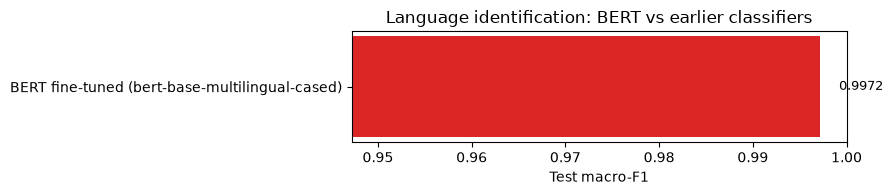

In [23]:
RESULTS_CSV = os.path.join(DATA_DIR, "lab6_results.csv")
MANUAL_RESULTS = {
    # "Logistic Regression": 0.0, "MLP (n=1 hidden layer)": 0.0, "LSTM": 0.0, "GRU": 0.0, "FastText Supervised": 0.0,
}

if os.path.exists(RESULTS_CSV):
    earlier = pd.read_csv(RESULTS_CSV)[["Classifier", "Val Macro-F1", "Test Macro-F1"]]
    print(f"Loaded earlier results from {RESULTS_CSV}")
elif MANUAL_RESULTS:
    earlier = pd.DataFrame({"Classifier": list(MANUAL_RESULTS), "Val Macro-F1": np.nan, "Test Macro-F1": list(MANUAL_RESULTS.values())})
    print("Using MANUAL_RESULTS")
else:
    earlier = pd.DataFrame(columns=["Classifier", "Val Macro-F1", "Test Macro-F1"])
    print("No earlier results found: add `results_df.to_csv('lab6_results.csv', index=False)` at the end of the earlier lab's\n"
          "comparison cell (or fill MANUAL_RESULTS above) and re-run this cell.")

bert_row = pd.DataFrame([{"Classifier": f"BERT fine-tuned ({MODEL_NAME})",
                          "Val Macro-F1": bert_val["macro_f1"], "Test Macro-F1": bert_test["macro_f1"]}])
comparison = pd.concat([earlier, bert_row], ignore_index=True).sort_values("Test Macro-F1", ascending=False).reset_index(drop=True)
comparison.index += 1
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(9, 0.55 * len(comparison) + 1.5))
colors = ["#dc2626" if "BERT" in n else "#64748b" for n in comparison["Classifier"][::-1]]
ax.barh(comparison["Classifier"][::-1], comparison["Test Macro-F1"][::-1], color=colors)
lo = max(0.0, comparison["Test Macro-F1"].min() - 0.05)
ax.set_xlim(lo, 1.0); ax.set_xlabel("Test macro-F1")
for y, v in enumerate(comparison["Test Macro-F1"][::-1]):
    ax.text(v + 0.002, y, f"{v:.4f}", va="center", fontsize=9)
ax.set_title("Language identification: BERT vs earlier classifiers"); plt.tight_layout(); plt.show()

### Cost vs. accuracy

| | Earlier models (LR / MLP / LSTM / GRU) | FastText supervised | Fine-tuned BERT |
|---|---|---|---|
| Parameters | thousands (≈ 1 k – 100 k) | ≈ 1.5 M (n-gram table) | ≈ 178 M (mBERT) |
| Input | average / sequence of **word** vectors (needs the pretrained fastText wiki vectors) | words + word bigrams | WordPieces, contextual |
| Training time | seconds – minutes on CPU | seconds | minutes – hours (GPU/MPS helps) |
| Inference | microseconds | microseconds | milliseconds per sentence |

## 7. Discussion (template — replace the *italics* with what your tables show)

1. **Overall accuracy.** *Report BERT's test macro-F1 and its rank in the comparison table. For a 5-language task written in clearly different scripts (Devanagari ×2, Bengali, Tamil, Arabic/Urdu) every model is expected to be very strong, so differences may be small – say whether they are larger than what you would expect from noise.*
2. **Where the errors are.** *Look at the confusion matrix: the hardest pair is normally **Hindi ↔ Marathi** (same Devanagari script, shared vocabulary), not languages with different scripts. Compare which pairs the earlier models and BERT confuse.*
3. **Why BERT can help.** *Pretrained on large multilingual text, it sees sub-word pieces and context, so unseen words are still handled (no out-of-vocabulary problem) and similar scripts are separated by context, not only by individual words.*
4. **Why it may not help much.** *Language ID is largely solved by character/word statistics; fastText-style models already reach very high scores at a tiny fraction of the cost. A gain of a fraction of a point may not justify ~100× the parameters and a much slower training/inference.*
5. **Caveats.** *One run (one seed), a 2-epoch budget, possibly a training subset, and a test set drawn from the same corpus (same domain) as training – accuracy on social-media text, transliterated or code-mixed text can be much lower.*

## 8. Troubleshooting

| Symptom | Fix |
|---|---|
| Too slow / disk thrashing | keep `FREEZE_EMBEDDINGS = True`, set `TRAIN_SUBSET = 10000`, `EPOCHS = 1`, `FREEZE_LAYERS = 6`, `BATCH_SIZE = 16`; close other apps; or use `distilbert-base-multilingual-cased`; or run on Google Colab / Kaggle (free GPU) |
| MPS out of memory | lower `BATCH_SIZE` to 16, or `MAX_LEN` to 48 |
| `sentencepiece` / tokenizer error for XLM-R / MuRIL | `%pip install sentencepiece protobuf`, restart the kernel |
| Model download blocked / slow | set `HF_TOKEN`, or download the model once from a browser-capable machine and point `MODEL_NAME` to the local folder |
| `numpy` / `torch` import errors | `%pip install "numpy<2"` and restart the kernel |

In [24]:
# optional: save the fine-tuned model and the results
SAVE_DIR = "lab10_bert_langid"
os.makedirs(SAVE_DIR, exist_ok=True)
model.save_pretrained(SAVE_DIR); tokenizer.save_pretrained(SAVE_DIR)
comparison.to_csv(os.path.join(SAVE_DIR, "comparison.csv"), index=False)
with open(os.path.join(SAVE_DIR, "bert_test_metrics.json"), "w") as f:
    json.dump({"model": MODEL_NAME, "test_macro_f1": bert_test["macro_f1"], "per_class": bert_test["per_class"]}, f, indent=2)
print("Saved to", SAVE_DIR)

Saved to lab10_bert_langid
